# Read file

In [9]:
import gzip
import numpy as np
import matplotlib.pyplot as plt

In [10]:
image_file = "/Users/kellyt/Documents/ml/HW8/MNISTdata/train-images-idx3-ubyte.gz"
label_file = "/Users/kellyt/Documents/ml/HW8/MNISTdata/train-labels-idx1-ubyte.gz"

with gzip.open(image_file, 'rb') as f:
    images = np.frombuffer(f.read(), dtype=np.uint8, offset=16)

with gzip.open(label_file, 'rb') as f:
    labels = np.frombuffer(f.read(), dtype=np.uint8, offset=8)

In [11]:
import gzip
import struct

with gzip.open(image_file, 'rb') as f:
    magic, num_images, rows, cols = struct.unpack(
        '>IIII', f.read(16)
    )

print("Magic number:", magic)
print("Number of images:", num_images)
print("Number of rows:", rows)
print("Number of columns:", cols)

Magic number: 2051
Number of images: 60000
Number of rows: 28
Number of columns: 28


In [12]:
images = images.reshape(-1, 28, 28) #28x28 is the original format

print(images.shape)
print(labels.shape)

(60000, 28, 28)
(60000,)


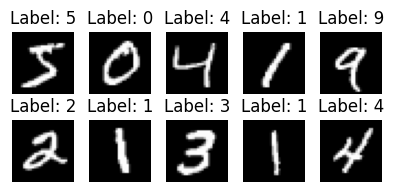

In [13]:
plt.figure(figsize=(4, 2))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(images[i], cmap='gray')
    plt.title(f"Label: {labels[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

# Data Preparation

In [14]:
# Flatten image
X = images.reshape(images.shape[0], -1)
y = labels

print(X.shape) # 784 cuz 28x28
print(y.shape)

(60000, 784)
(60000,)


In [15]:
X = X.astype('float32') / 255.0 # pixel values range from 0 to 255
X

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], dtype=float32)

In [16]:
print("Feature matrix:", X.shape)
print("Labels:", y.shape)
print("Pixel range:", X.min(), "to", X.max())

Feature matrix: (60000, 784)
Labels: (60000,)
Pixel range: 0.0 to 1.0


# Experiment 1 — Clustering using original pixel features

## K-Means

In [17]:
from sklearn.cluster import KMeans

kmeans_raw = KMeans(
    n_clusters=10,
    init="k-means++",
    n_init=10,
    max_iter=300,
    random_state=42
)

labels_kmeans_raw = kmeans_raw.fit_predict(X)

print("K-Means cluster sizes:")
print(np.bincount(labels_kmeans_raw))

K-Means cluster sizes:
[8839 5960 3098 5714 3198 8929 6514 4675 7435 5638]


## Hierachical

In [18]:
from sklearn.cluster import Birch

birch_raw = Birch(
    n_clusters=10,
    threshold=4.0,
    branching_factor=50
)

labels_birch_raw = birch_raw.fit_predict(X)

print("BIRCH cluster sizes:")
print(np.bincount(labels_birch_raw))

print(
    "Number of intermediate subclusters:",
    len(birch_raw.subcluster_centers_)
)

BIRCH cluster sizes:
[14606 13050  5482  3451  7170  3918  3151  2710  1746  4716]
Number of intermediate subclusters: 18991


# Experiment 2 — PCA followed by clustering

In [ ]:
from sklearn.decomposition import PCA

pca = PCA(
    n_components=50,
    svd_solver="randomized",
    random_state=42
)

X_pca = pca.fit_transform(X)

print("Original data shape:", X.shape)
print("PCA data shape:", X_pca.shape)

print(
    "Total explained variance:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

Original data shape: (60000, 784)
PCA data shape: (60000, 50)
Total explained variance: 82.46 %


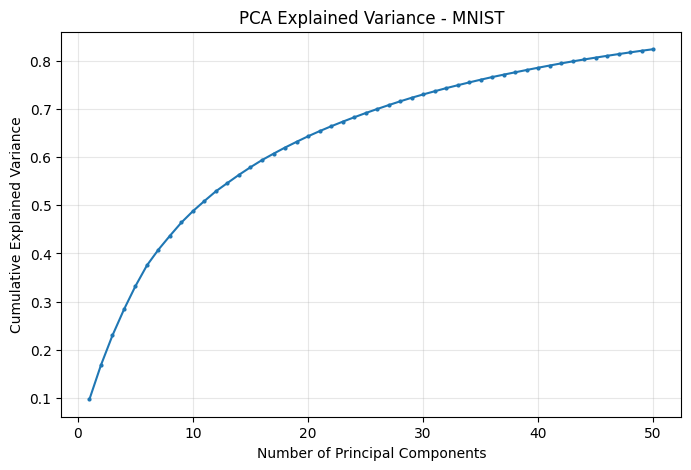

In [ ]:
cumulative_variance = np.cumsum(
    pca.explained_variance_ratio_
)

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 51),
    cumulative_variance,
    marker=".",
    markersize=4
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA Explained Variance - MNIST")
plt.grid(alpha=0.3)
plt.show()

## K-means on PCA

In [21]:
kmeans_pca = KMeans(
    n_clusters=10,
    init="k-means++",
    n_init=10,
    max_iter=300,
    random_state=42
)

labels_kmeans_pca = kmeans_pca.fit_predict(X_pca)

print("K-Means (PCA) cluster sizes:")
print(np.bincount(labels_kmeans_pca))

K-Means (PCA) cluster sizes:
[8934 5727 5596 3104 6520 8852 5983 3179 7434 4671]


## Hierachical on PCA

In [22]:
birch_pca = Birch(
    n_clusters=10,
    threshold=4.0,
    branching_factor=50
)

labels_birch_pca = birch_pca.fit_predict(X_pca)

print("BIRCH (PCA) cluster sizes:")
print(np.bincount(labels_birch_pca))

print(
    "Number of intermediate subclusters:",
    len(birch_pca.subcluster_centers_)
)

BIRCH (PCA) cluster sizes:
[ 5069  5174 25078  5691  5166  2015  3993  1974  3605  2235]
Number of intermediate subclusters: 4328


# Compare on all 4 experiments

## on PCA

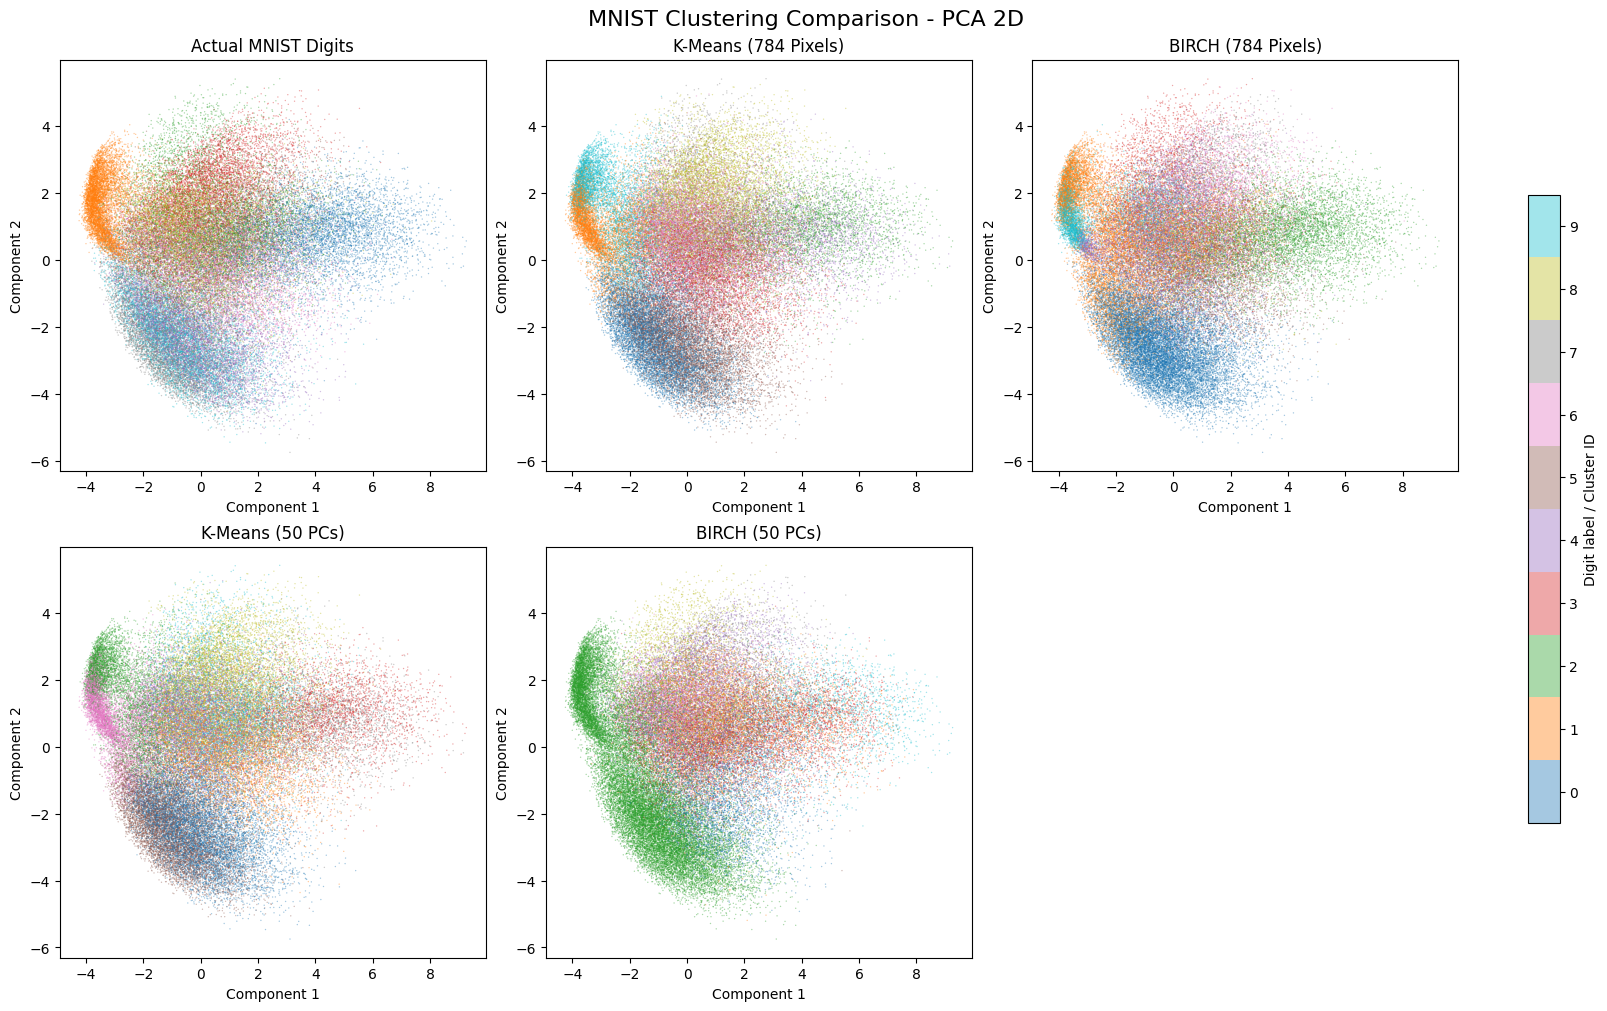

In [23]:
# Use the first two principal components for visualization
X_2d = X_pca[:, :2]

results = {
    "K-Means (784 Pixels)": labels_kmeans_raw,
    "BIRCH (784 Pixels)": labels_birch_raw,
    "K-Means (50 PCs)": labels_kmeans_pca,
    "BIRCH (50 PCs)": labels_birch_pca
}

def plot_all_clusters(embedding, title):
    fig, axes = plt.subplots(
        2, 3, figsize=(16, 10),
        constrained_layout=True
    )

    plots = [
        ("Actual MNIST Digits", y),
        *list(results.items())
    ]

    for ax, (name, cluster_labels) in zip(
        axes.flat, plots
    ):
        sc = ax.scatter(
            embedding[:, 0],
            embedding[:, 1],
            c=cluster_labels,
            cmap="tab10",
            vmin=-0.5,
            vmax=9.5,
            s=1,
            alpha=0.4,
            linewidths=0,
            rasterized=True
        )

        ax.set_title(name)
        ax.set_xlabel("Component 1")
        ax.set_ylabel("Component 2")

    # Hide the unused sixth subplot
    axes.flat[5].axis("off")

    fig.colorbar(
        sc,
        ax=axes.ravel().tolist(),
        ticks=range(10),
        shrink=0.7,
        label="Digit label / Cluster ID"
    )

    fig.suptitle(title, fontsize=16)
    plt.show()


plot_all_clusters(
    X_2d,
    "MNIST Clustering Comparison - PCA 2D"
)

## on UMAP

/Users/kellyt/Documents/ml/.venv-local/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/kellyt/Documents/ml/.venv-local/lib/python3.9/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP shape: (60000, 2)


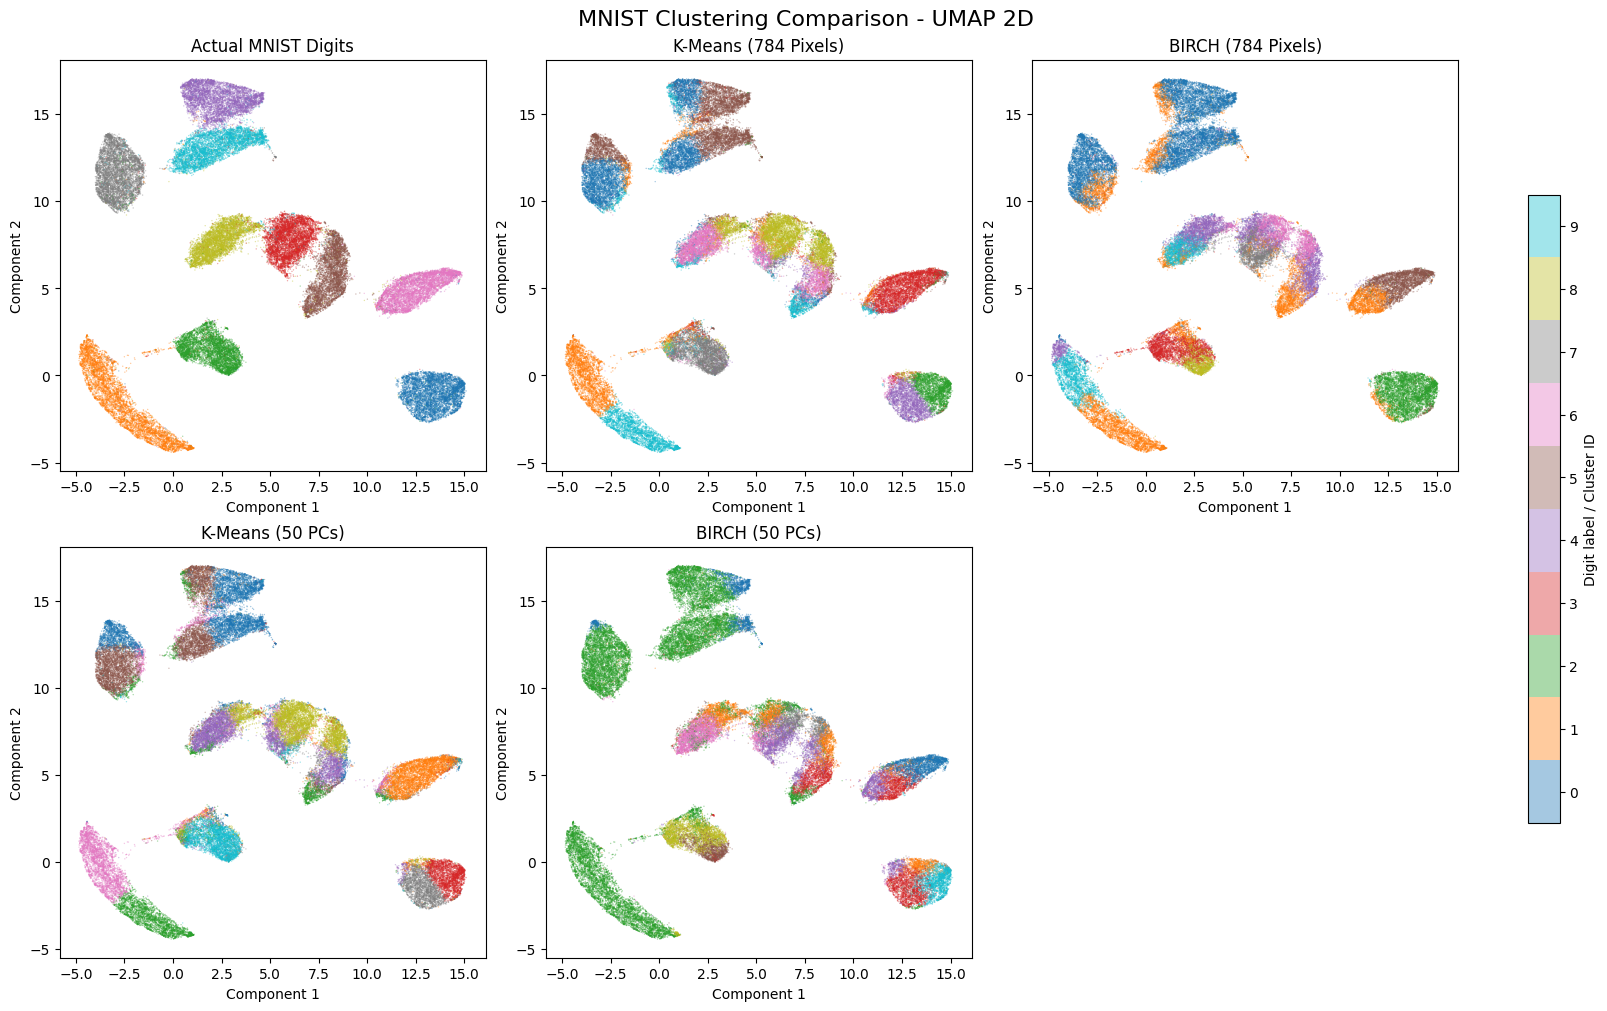

In [24]:
# Install only if necessary:
# %pip install umap-learn

import umap

umap_model = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric="euclidean",
    random_state=42,
    low_memory=True
)

X_umap = umap_model.fit_transform(X_pca)

print("UMAP shape:", X_umap.shape)

plot_all_clusters(
    X_umap,
    "MNIST Clustering Comparison - UMAP 2D"
)

## Metrics

In [31]:
import pandas as pd
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score
)

summary = []

for name, cluster_labels in results.items():

    # Cluster vs actual digit counts
    table = pd.crosstab(
        pd.Series(cluster_labels, name="Cluster"),
        pd.Series(y, name="Digit")
    )

    # Purity
    purity = table.max(axis=1).sum() / len(y)

    # External evaluation metrics
    ari = adjusted_rand_score(y, cluster_labels)
    nmi = normalized_mutual_info_score(y, cluster_labels)

    summary.append({
        "Method": name,
        "Clusters Found": len(np.unique(cluster_labels)),
        "ARI": ari,
        "NMI": nmi,
        "Purity": purity
    })

results_df = pd.DataFrame(summary)

print(results_df.round(4).to_string(index=False))

              Method  Clusters Found    ARI    NMI  Purity
K-Means (784 Pixels)              10 0.3609 0.4906  0.5910
  BIRCH (784 Pixels)              10 0.3316 0.5395  0.5254
    K-Means (50 PCs)              10 0.3602 0.4900  0.5906
      BIRCH (50 PCs)              10 0.2237 0.4452  0.4430


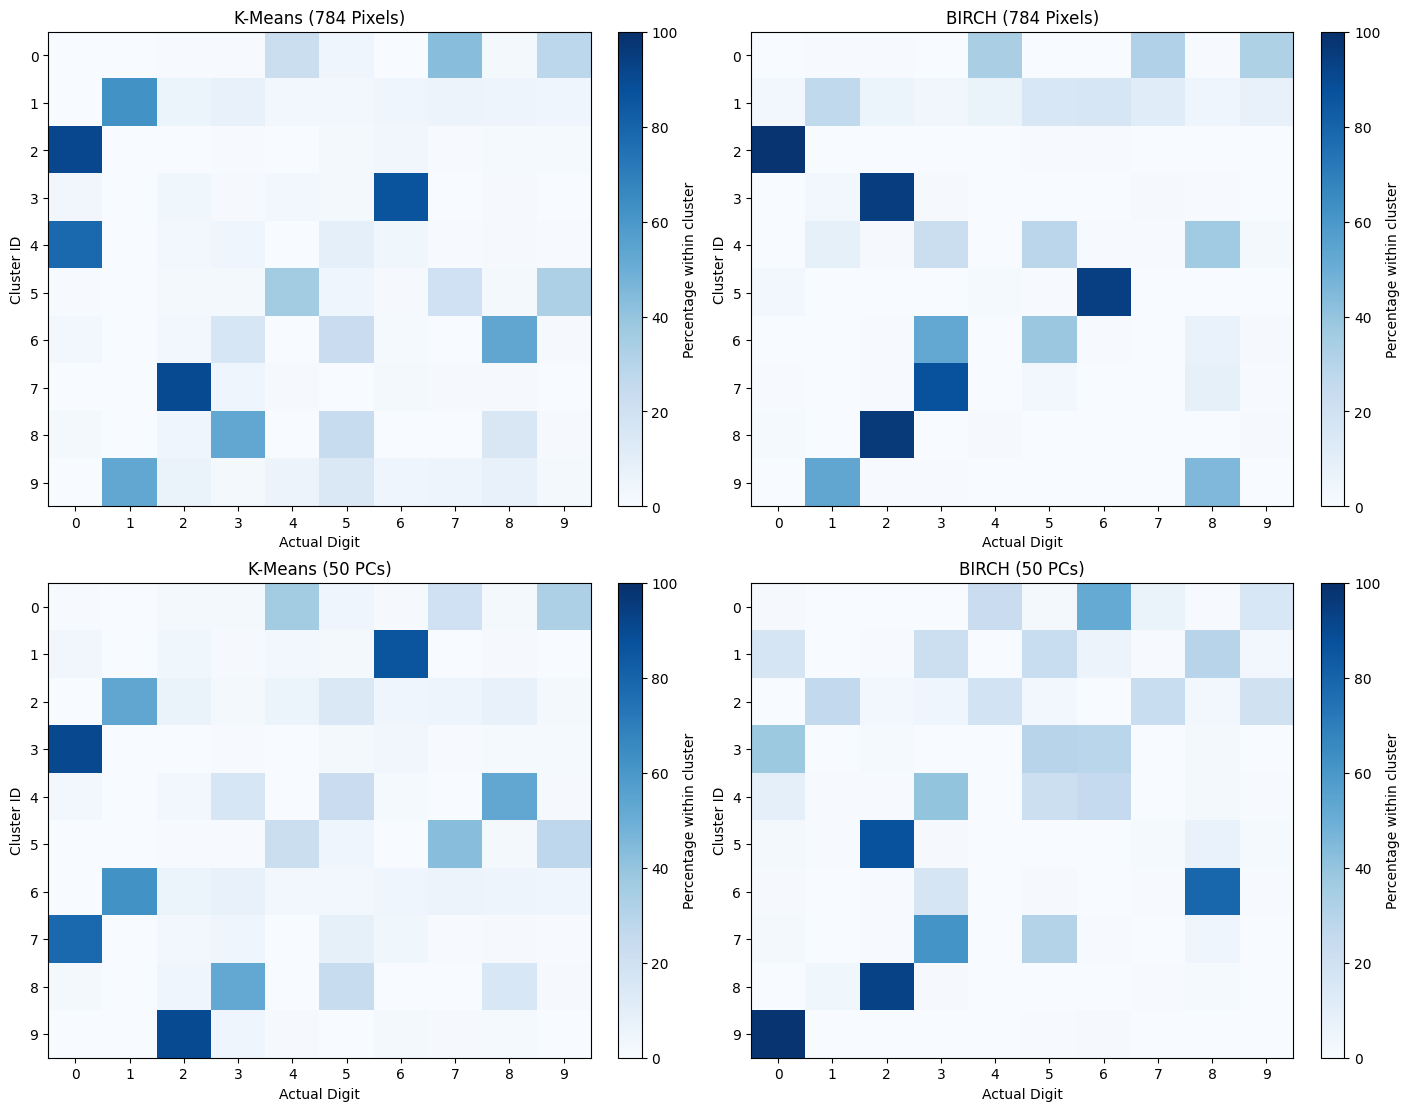

In [26]:
fig, axes = plt.subplots(
    2, 2, figsize=(14, 11),
    constrained_layout=True
)

for ax, (name, cluster_labels) in zip(
    axes.flat, results.items()
):
    # Rows: predicted clusters
    # Columns: actual digits
    counts = np.zeros((10, 10), dtype=int)

    np.add.at(
        counts,
        (cluster_labels.astype(int), y.astype(int)),
        1
    )

    # Percentage of each digit within its cluster
    row_totals = counts.sum(axis=1, keepdims=True)

    percentages = (
        counts / np.maximum(row_totals, 1) * 100
    )

    im = ax.imshow(
        percentages,
        cmap="Blues",
        vmin=0,
        vmax=100,
        aspect="auto"
    )

    ax.set_title(name)
    ax.set_xlabel("Actual Digit")
    ax.set_ylabel("Cluster ID")
    ax.set_xticks(range(10))
    ax.set_yticks(range(10))

    fig.colorbar(
        im, ax=ax,
        label="Percentage within cluster"
    )

plt.show()

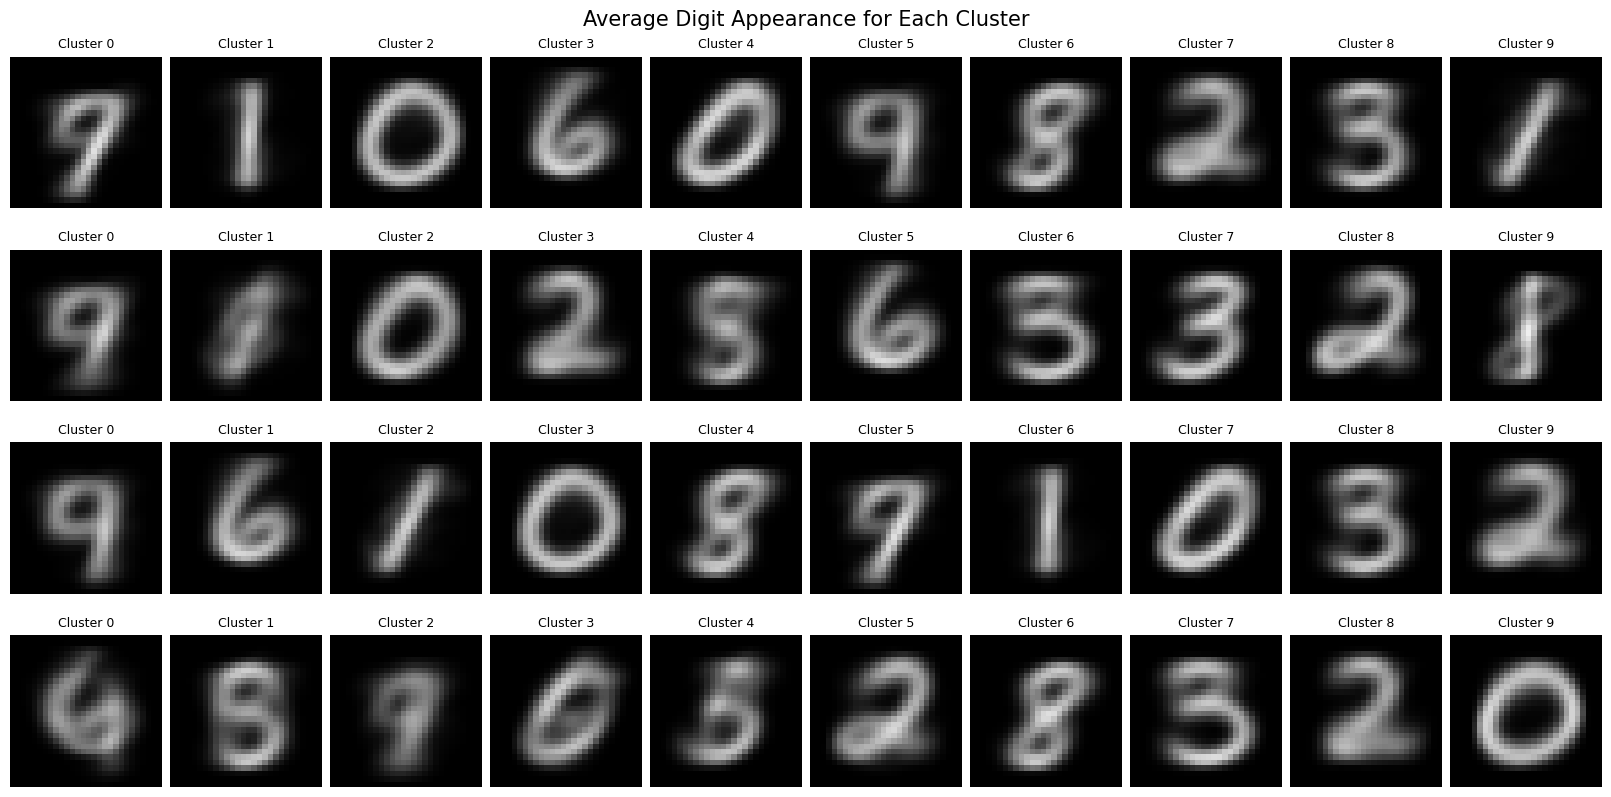

In [27]:
fig, axes = plt.subplots(
    4, 10, figsize=(16, 8),
    constrained_layout=True
)

for row, (name, cluster_labels) in enumerate(
    results.items()
):
    for cluster_id in range(10):

        ax = axes[row, cluster_id]

        cluster_images = images[
            cluster_labels == cluster_id
        ]

        if len(cluster_images) > 0:
            mean_image = cluster_images.mean(axis=0)

            ax.imshow(
                mean_image,
                cmap="gray",
                vmin=0,
                vmax=255
            )

        ax.set_title(f"Cluster {cluster_id}", fontsize=9)
        ax.axis("off")

    axes[row, 0].set_ylabel(
        name,
        fontsize=10,
        rotation=90,
        labelpad=12
    )

plt.suptitle(
    "Average Digit Appearance for Each Cluster",
    fontsize=15
)
plt.show()

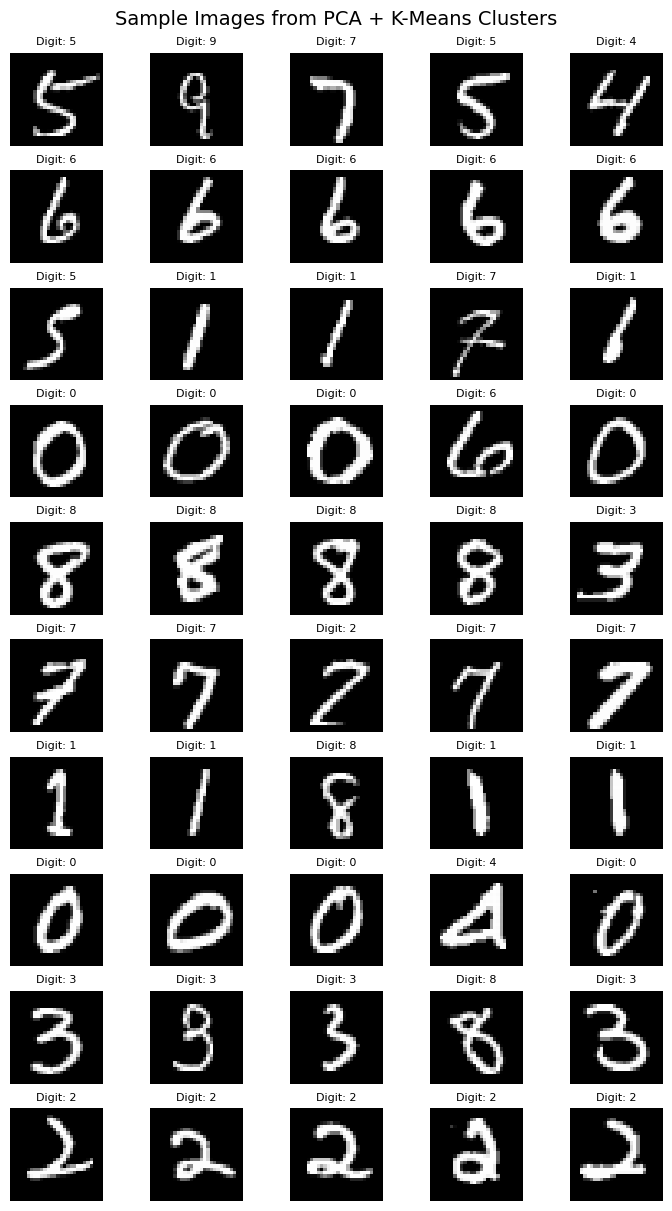

In [29]:
rng = np.random.default_rng(42)

cluster_labels = labels_kmeans_pca

fig, axes = plt.subplots(
    10, 5, figsize=(7, 12),
    constrained_layout=True
)

for cluster_id in range(10):

    indices = np.where(
        cluster_labels == cluster_id
    )[0]

    if len(indices) == 0:
        for ax in axes[cluster_id]:
            ax.axis("off")
        continue

    selected = rng.choice(
        indices,
        size=5,
        replace=len(indices) < 5
    )

    for j, idx in enumerate(selected):
        ax = axes[cluster_id, j]

        ax.imshow(images[idx], cmap="gray")
        ax.set_title(f"Digit: {y[idx]}", fontsize=8)
        ax.axis("off")

    axes[cluster_id, 0].set_ylabel(
        f"Cluster {cluster_id}",
        rotation=90
    )

plt.suptitle(
    "Sample Images from PCA + K-Means Clusters",
    fontsize=14
)
plt.show()